## Step 1 -- Setup the notebook

In [ ]:

# OpenWhistle: Environment setup
!pip -q install -U datasets librosa soundfile


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:

from datasets import load_dataset, Audio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display

DATASET_ID = "dolphinteam/OpenWhistle-Classification-Finetuning"

dataset = load_dataset(DATASET_ID, "all-review-sample")

# Decode audio when accessed
dataset = dataset.cast_column("audio", Audio(decode=True))

print(dataset)
print("\nAvailable columns:")
print(dataset["train"].column_names)


README.md:   0%|          | 0.00/14.4k [00:00<?, ?B/s]

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


all-review-sample/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B /  139MB            

all-review-sample/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

all-review-sample/validation-00000-of-00(…): reconstructing file:   0%|          |  0.00B / 30.5MB            

...

all-review-sample/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/336 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/72 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/72 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['audio', 'label', 'name', 'onset', 'offset', 'duration', 'recording_duration', 'whistle_type', 'whistle_name', 'f0_time', 'f0_hz', 'f0_conf', 'f0_ok', 'f0_bad_reason', 'f0_spectrogram', 'snr_db'],
        num_rows: 336
    })
    validation: Dataset({
        features: ['audio', 'label', 'name', 'onset', 'offset', 'duration', 'recording_duration', 'whistle_type', 'whistle_name', 'f0_time', 'f0_hz', 'f0_conf', 'f0_ok', 'f0_bad_reason', 'f0_spectrogram', 'snr_db'],
        num_rows: 72
    })
    test: Dataset({
        features: ['audio', 'label', 'name', 'onset', 'offset', 'duration', 'recording_duration', 'whistle_type', 'whistle_name', 'f0_time', 'f0_hz', 'f0_conf', 'f0_ok', 'f0_bad_reason', 'f0_spectrogram', 'snr_db'],
        num_rows: 72
    })
})

Available columns:
['audio', 'label', 'name', 'onset', 'offset', 'duration', 'recording_duration', 'whistle_type', 'whistle_name', 'f0_time', 'f0_hz', 'f0_conf', 'f0_ok', 'f0_bad_rea

In [ ]:

for split_name, split_data in dataset.items():
    print(f"\n{split_name.upper()}: {len(split_data)} examples")

    df = split_data.to_pandas()

    if "label" in df.columns:
        print("\nClass distribution:")
        print(df["label"].value_counts().sort_index())

    if "name" in df.columns:
        print("\nClass names:")
        print(df.groupby("label")["name"].first().to_dict())



TRAIN: 336 examples

Class distribution:
label
0      2
1      1
2     26
3     14
4    118
5     21
6     90
7     36
8      3
9     25
Name: count, dtype: int64

Class names:
{0: 'Exp_08_Jan_2020_1245pm', 1: 'Exp_01_Feb_2020_1145am', 2: 'Exp_06_Dec_2019_1345pm', 3: 'Exp_04_Feb_2020_1245pm', 4: 'Exp_03_Mar_2020_1345pm', 5: 'Exp_11_Dec_2019_1145am', 6: 'Exp_06_Feb_2020_1345pm', 7: 'Exp_14_Jan_2020_1045am', 8: 'Exp_07_Dec_2019_1245pm', 9: 'Exp_05_Jan_2020_1345pm'}

VALIDATION: 72 examples

Class distribution:
label
0     1
1     1
2     5
3     3
4    25
5     4
6    19
7     7
8     2
9     5
Name: count, dtype: int64

Class names:
{0: 'Exp_03_Jan_2020_1045am', 1: 'Exp_22_Nov_2019_0845am', 2: 'Exp_20_Nov_2019_0845am', 3: 'Exp_16_Feb_2020_1545pm', 4: 'Exp_06_Feb_2020_1545pm', 5: 'Exp_17_Jan_2020_1045am', 6: 'Exp_07_Mar_2020_1345pm', 7: 'Exp_22_Nov_2019_1345pm', 8: 'Exp_11_Mar_2020_0945am', 9: 'Exp_09_Feb_2020_1345pm'}

TEST: 72 examples

Class distribution:
label
0     1
1     1
2     

Class label: 7
Class name: Exp_14_Jan_2020_1045am
Sample rate: 44100 Hz
Duration: 0.197 seconds
Audio shape: (8667,)


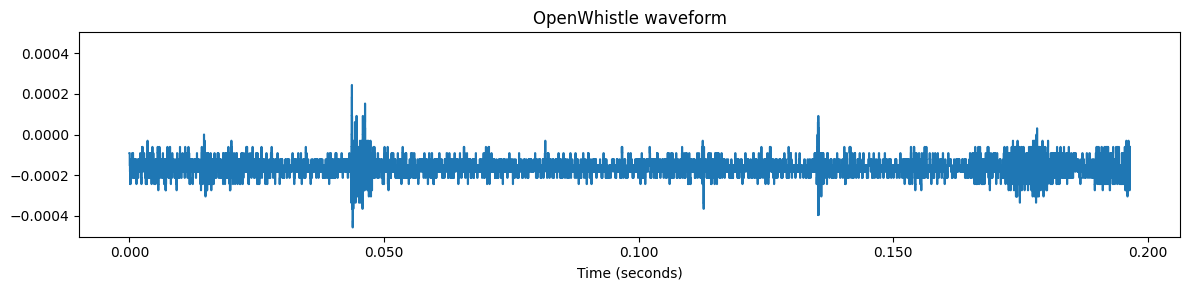

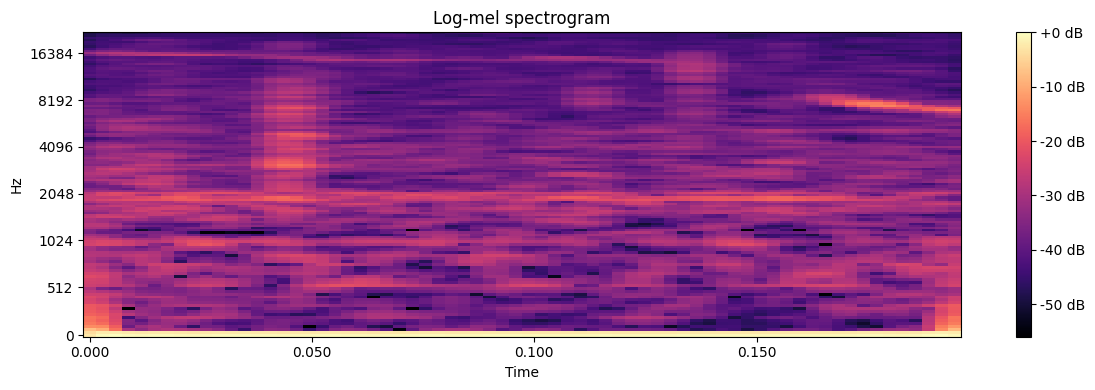

In [ ]:

sample = dataset["train"][0]

audio = sample["audio"]["array"]
sr = sample["audio"]["sampling_rate"]

print("Class label:", sample["label"])
print("Class name:", sample.get("name"))
print("Sample rate:", sr, "Hz")
print("Duration:", round(len(audio) / sr, 3), "seconds")
print("Audio shape:", audio.shape)

# Waveform
plt.figure(figsize=(12, 3))
librosa.display.waveshow(audio, sr=sr)
plt.title("OpenWhistle waveform")
plt.xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

# Log-mel spectrogram
mel = librosa.feature.melspectrogram(
    y=audio.astype(np.float32),
    sr=sr,
    n_mels=128,
    n_fft=1024,
    hop_length=128
)

mel_db = librosa.power_to_db(mel, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=128,
    x_axis="time",
    y_axis="mel"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Log-mel spectrogram")
plt.tight_layout()
plt.show()


## Load the full dataset

In [2]:

from datasets import load_dataset, Audio
import pandas as pd

DATASET_ID = "dolphinteam/OpenWhistle-Classification-Finetuning"

dataset = load_dataset(DATASET_ID, "all")

# Get the official mapping from integer labels to whistle categories
label_names = dataset["train"].features["label"].names

print("Official class mapping:")
for i, name in enumerate(label_names):
    print(f"{i}: {name}")

print("\nSplit sizes:")
for split, data in dataset.items():
    print(f"{split}: {len(data)} examples")

print("\nTraining class distribution:")
train_df = dataset["train"].to_pandas()
print(train_df["label"].value_counts().sort_index())


Official class mapping:
0: NSW_3
1: NSW_2
2: NSW_1
3: SW_Dana
4: SW_Luna
5: SW_Nana
6: SW_Neo
7: SW_Nikita
8: SW_Shy
9: SW_Yosefa

Split sizes:
train: 5848 examples
validation: 1253 examples
test: 1253 examples

Training class distribution:
label
0      31
1      19
2     460
3     235
4    2054
5     365
6    1567
7     622
8      57
9     438
Name: count, dtype: int64


In [3]:

dataset = dataset.cast_column("audio", Audio(decode=True))

for i in range(5):
    sample = dataset["train"][i]
    print(
        f"Sample {i}: "
        f"class={label_names[sample['label']]}, "
        f"sampling_rate={sample['audio']['sampling_rate']} Hz, "
        f"duration={len(sample['audio']['array']) / sample['audio']['sampling_rate']:.3f}s"
    )


Sample 0: class=NSW_1, sampling_rate=44100 Hz, duration=1.230s
Sample 1: class=SW_Luna, sampling_rate=44100 Hz, duration=0.548s
Sample 2: class=SW_Luna, sampling_rate=44100 Hz, duration=1.463s
Sample 3: class=SW_Neo, sampling_rate=44100 Hz, duration=0.612s
Sample 4: class=SW_Luna, sampling_rate=44100 Hz, duration=0.776s


## Analyze the audio characteristics

In [4]:

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

def inspect_audio_split(split_data, split_name):
    """Collect duration and sampling-rate statistics for an audio split."""
    rows = []

    for sample in tqdm(split_data, desc=f"Inspecting {split_name}"):
        audio = sample["audio"]
        sr = audio["sampling_rate"]
        waveform = audio["array"]

        rows.append({
            "label": sample["label"],
            "duration": len(waveform) / sr,
            "sampling_rate": sr,
            "num_samples": len(waveform),
        })

    return pd.DataFrame(rows)


train_stats = inspect_audio_split(dataset["train"], "train")
val_stats = inspect_audio_split(dataset["validation"], "validation")
test_stats = inspect_audio_split(dataset["test"], "test")

print("Training duration statistics (seconds):")
print(train_stats["duration"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]))

print("\nSampling rates:")
print(train_stats["sampling_rate"].value_counts())

print("\nDuration by class:")
print(
    train_stats.groupby("label")["duration"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)


Inspecting train:   0%|          | 0/5848 [00:00<?, ?it/s]

Inspecting validation:   0%|          | 0/1253 [00:00<?, ?it/s]

Inspecting test:   0%|          | 0/1253 [00:00<?, ?it/s]

Training duration statistics (seconds):
count    5848.000000
mean        0.842831
std         0.292327
min         0.040431
5%          0.391907
25%         0.634671
50%         0.835567
75%         1.025011
95%         1.323565
max         2.213469
Name: duration, dtype: float64

Sampling rates:
sampling_rate
44100    5848
Name: count, dtype: int64

Duration by class:
       count   mean  median    min    max
label                                    
0         31  0.642   0.605  0.328  1.112
1         19  0.688   0.484  0.222  1.875
2        460  0.853   0.796  0.165  1.820
3        235  0.978   0.977  0.200  1.863
4       2054  0.855   0.847  0.142  2.070
5        365  0.884   0.855  0.176  2.213
6       1567  0.911   0.901  0.096  2.199
7        622  0.585   0.524  0.091  1.710
8         57  0.885   0.917  0.250  1.489
9        438  0.803   0.765  0.040  1.352


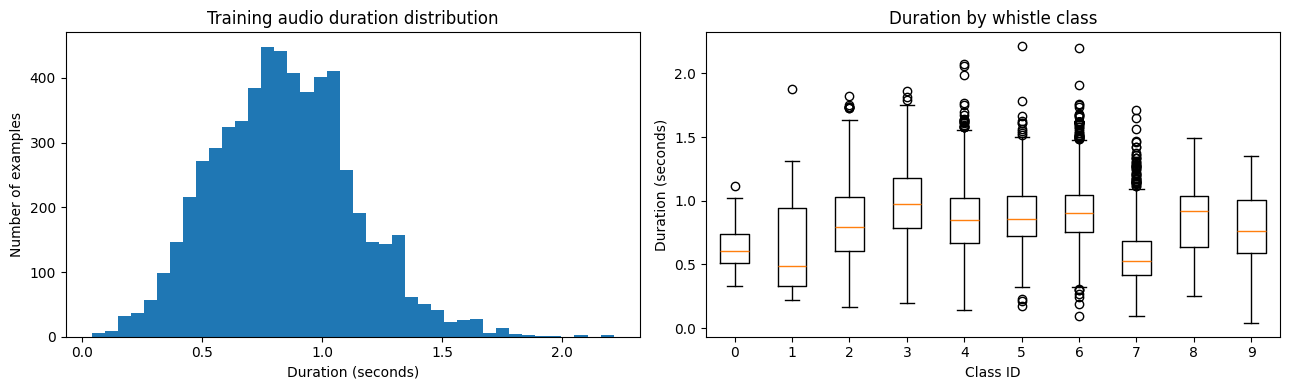

In [5]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(train_stats["duration"], bins=40)
axes[0].set_title("Training audio duration distribution")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Number of examples")

class_durations = [
    train_stats.loc[train_stats["label"] == label, "duration"].values
    for label in sorted(train_stats["label"].unique())
]

axes[1].boxplot(class_durations, tick_labels=sorted(train_stats["label"].unique()))
axes[1].set_title("Duration by whistle class")
axes[1].set_xlabel("Class ID")
axes[1].set_ylabel("Duration (seconds)")

plt.tight_layout()
plt.show()


## Preprocessing

In [6]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio

from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Audio preprocessing configuration
TARGET_SR = 22050
DURATION = 1.5
NUM_SAMPLES = int(TARGET_SR * DURATION)

N_MELS = 128
N_FFT = 1024
HOP_LENGTH = 256

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=TARGET_SR,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0,
    f_max=TARGET_SR / 2,
    power=2.0,
)

class OpenWhistleDataset(Dataset):
    """Create fixed-size log-mel spectrograms from OpenWhistle audio."""

    def __init__(self, split):
        self.data = dataset[split]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]

        waveform = torch.as_tensor(
            item["audio"]["array"], dtype=torch.float32
        ).flatten()

        original_sr = item["audio"]["sampling_rate"]

        # Resample only if necessary
        if original_sr != TARGET_SR:
            waveform = torchaudio.functional.resample(
                waveform, original_sr, TARGET_SR
            )

        # Normalize waveform amplitude
        waveform = waveform - waveform.mean()
        waveform = waveform / waveform.abs().max().clamp_min(1e-8)

        # Fixed duration: right-pad or right-truncate
        if waveform.numel() < NUM_SAMPLES:
            waveform = F.pad(waveform, (0, NUM_SAMPLES - waveform.numel()))
        else:
            waveform = waveform[:NUM_SAMPLES]

        # Log-mel spectrogram
        mel = mel_transform(waveform)
        log_mel = torch.log(mel.clamp_min(1e-6))

        # Per-example normalization
        log_mel = (
            log_mel - log_mel.mean()
        ) / log_mel.std().clamp_min(1e-6)

        # ResNet expects channel, frequency, time
        return log_mel.unsqueeze(0), int(item["label"])


train_ds = OpenWhistleDataset("train")
val_ds = OpenWhistleDataset("validation")
test_ds = OpenWhistleDataset("test")

x, y = train_ds[0]
print("Spectrogram shape:", x.shape)
print("Label:", y)
print("Finite values:", torch.isfinite(x).all().item())


Device: cuda
Spectrogram shape: torch.Size([1, 128, 130])
Label: 2
Finite values: True


## Build ResNet-18 Baseline

In [7]:

NUM_CLASSES = 10
BATCH_SIZE = 32

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

model = resnet18(weights=None)

# Convert the first layer to accept one spectrogram channel
model.conv1 = nn.Conv2d(
    1, 64, kernel_size=7, stride=2, padding=3, bias=False
)

model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(DEVICE)

# Class-weighted loss: inverse-frequency weighting
counts = np.bincount(
    [int(item["label"]) for item in dataset["train"]],
    minlength=NUM_CLASSES
)

class_weights = counts.sum() / (
    NUM_CLASSES * np.maximum(counts, 1)
)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-3, weight_decay=1e-4
)

print("Model ready.")
print("Training class counts:", counts)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))


Model ready.
Training class counts: [  31   19  460  235 2054  365 1567  622   57  438]
Number of parameters: 11175370


In [8]:

from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

def run_epoch(loader, training=False):
    model.train(training)
    total_loss = 0.0
    all_targets, all_preds = [], []

    for x, y in tqdm(loader, leave=False):
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * y.size(0)
        all_targets.extend(y.cpu().numpy())
        all_preds.extend(logits.argmax(dim=1).cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_targets, all_preds),
        "macro_f1": f1_score(
            all_targets, all_preds, average="macro", zero_division=0
        ),
    }


best_val_f1 = -1
EPOCHS = 10

for epoch in range(EPOCHS):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        torch.save(model.state_dict(), "openwhistle_resnet18_best.pt")

print("Best validation macro-F1:", best_val_f1)


  0%|          | 0/183 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch 01 | Train loss: 2.4057 | Val loss: 2.3518 | Val macro-F1: 0.0748 | Val accuracy: 0.0926


  0%|          | 0/183 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

...

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch 09 | Train loss: 2.0238 | Val loss: 2.0480 | Val macro-F1: 0.1942 | Val accuracy: 0.2666


  0%|          | 0/183 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch 10 | Train loss: 1.9593 | Val loss: 2.0226 | Val macro-F1: 0.2087 | Val accuracy: 0.2522
Best validation macro-F1: 0.2086900463778385


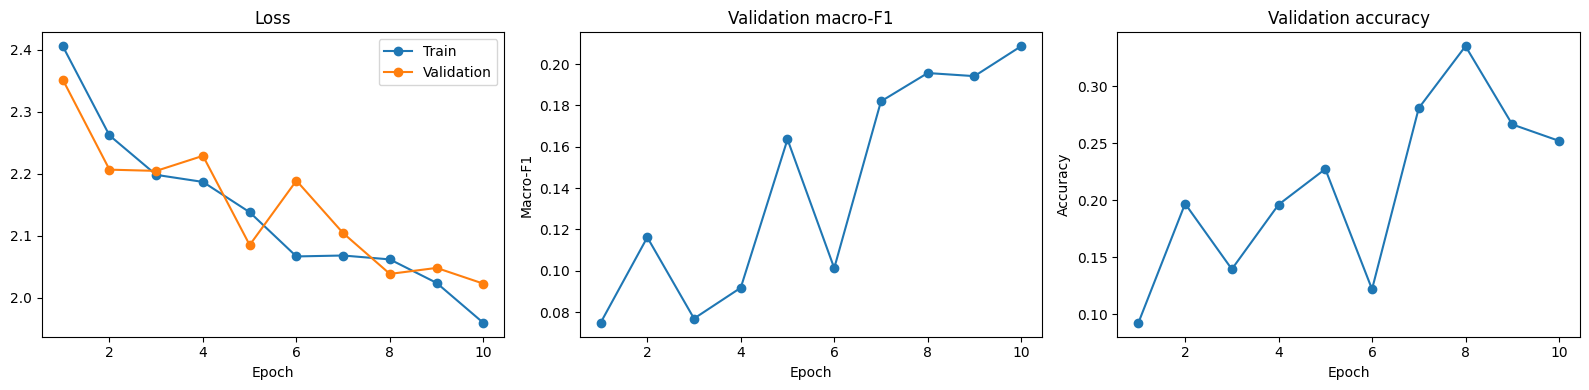

In [9]:

import matplotlib.pyplot as plt

train_loss = [2.4057, 2.2617, 2.1981, 2.1867, 2.1378,
              2.0665, 2.0680, 2.0617, 2.0238, 1.9593]

val_loss = [2.3518, 2.2065, 2.2045, 2.2288, 2.0849,
            2.1888, 2.1041, 2.0383, 2.0480, 2.0226]

val_f1 = [0.0748, 0.1162, 0.0769, 0.0918, 0.1636,
          0.1013, 0.1820, 0.1957, 0.1942, 0.2087]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
epochs = range(1, 11)

axes[0].plot(epochs, train_loss, marker="o", label="Train")
axes[0].plot(epochs, val_loss, marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs, val_f1, marker="o")
axes[1].set_title("Validation macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")

axes[2].plot(epochs, [0.0926, 0.1971, 0.1397, 0.1963, 0.2275,
                      0.1221, 0.2809, 0.3352, 0.2666, 0.2522],
             marker="o")
axes[2].set_title("Validation accuracy")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy")

plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

       NSW_3      0.011     0.571     0.021         7
       NSW_2      0.000     0.000     0.000         4
       NSW_1      0.558     0.586     0.571        99
     SW_Dana      0.103     0.280     0.151        50
     SW_Luna      0.570     0.111     0.186       440
     SW_Nana      0.329     0.346     0.338        78
      SW_Neo      0.482     0.369     0.418       336
   SW_Nikita      0.330     0.256     0.288       133
      SW_Shy      0.019     0.083     0.031        12
   SW_Yosefa      0.192     0.053     0.083        94

    accuracy                          0.252      1253
   macro avg      0.259     0.266     0.209      1253
weighted avg      0.448     0.252     0.287      1253



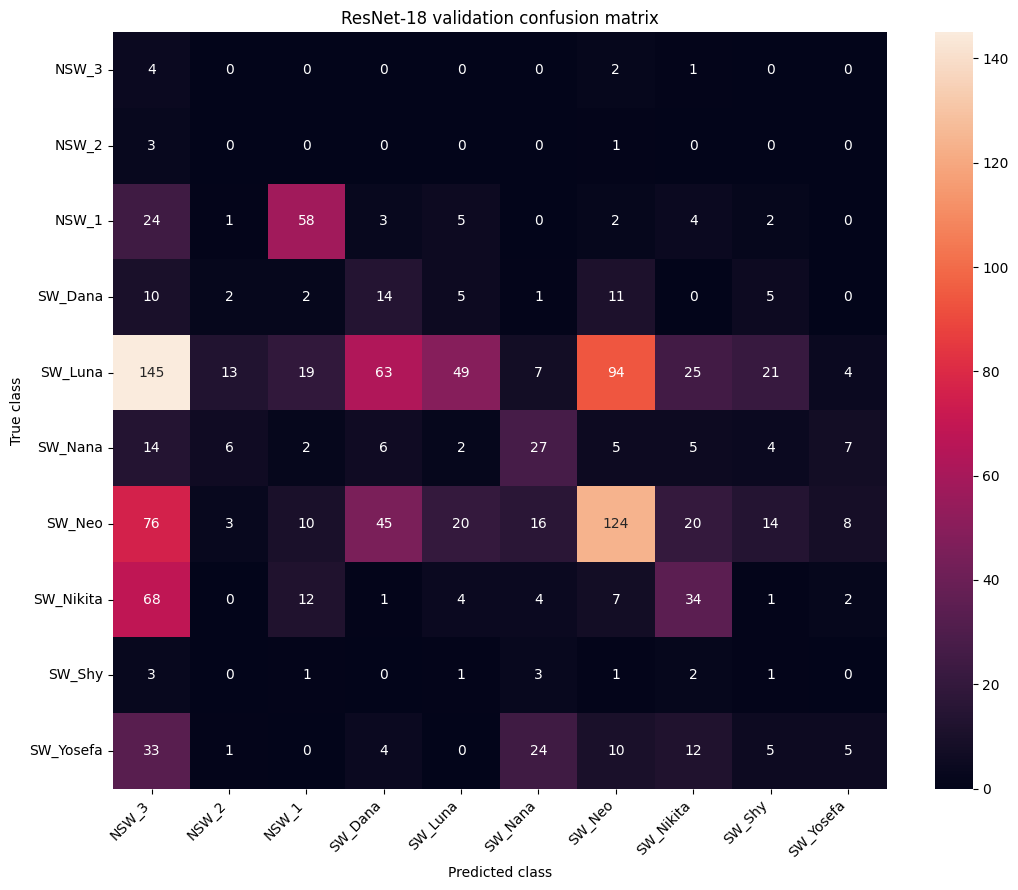

In [10]:

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Restore the best validation checkpoint
model.load_state_dict(
    torch.load("openwhistle_resnet18_best.pt", map_location=DEVICE)
)
model.eval()

all_targets, all_preds = [], []

with torch.no_grad():
    for x, y in val_loader:
        logits = model(x.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu().numpy()

        all_preds.extend(predictions)
        all_targets.extend(y.numpy())

label_names = dataset["train"].features["label"].names
class_ids = list(range(len(label_names)))

print(classification_report(
    all_targets,
    all_preds,
    labels=class_ids,
    target_names=label_names,
    zero_division=0,
    digits=3
))

cm = confusion_matrix(all_targets, all_preds, labels=class_ids)

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_names,
    yticklabels=label_names
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("ResNet-18 validation confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Train an unweighted baseline

In [11]:

# Controlled ablation: ordinary cross-entropy
import copy
import torch
import torch.nn as nn
from torchvision.models import resnet18
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

torch.manual_seed(42)

model_unweighted = resnet18(weights=None)
model_unweighted.conv1 = nn.Conv2d(
    1, 64, kernel_size=7, stride=2, padding=3, bias=False
)
model_unweighted.fc = nn.Linear(
    model_unweighted.fc.in_features, 10
)
model_unweighted = model_unweighted.to(DEVICE)

criterion_unweighted = nn.CrossEntropyLoss()

optimizer_unweighted = torch.optim.AdamW(
    model_unweighted.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

def run_unweighted_epoch(loader, training=False):
    model_unweighted.train(training)
    total_loss = 0.0
    targets, predictions = [], []

    for x, y in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)

        if training:
            optimizer_unweighted.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model_unweighted(x)
            loss = criterion_unweighted(logits, y)

            if training:
                loss.backward()
                optimizer_unweighted.step()

        total_loss += loss.item() * y.size(0)
        targets.extend(y.cpu().tolist())
        predictions.extend(logits.argmax(1).detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets, predictions,
            labels=list(range(10)),
            average="macro",
            zero_division=0
        )
    }

best_unweighted_f1 = -1.0
unweighted_history = []

for epoch in range(10):
    tr = run_unweighted_epoch(train_loader, training=True)
    va = run_unweighted_epoch(val_loader, training=False)

    unweighted_history.append({
        "epoch": epoch + 1,
        "train_loss": tr["loss"],
        "val_loss": va["loss"],
        "val_macro_f1": va["macro_f1"],
        "val_accuracy": va["accuracy"]
    })

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {tr['loss']:.4f} | "
        f"Val loss: {va['loss']:.4f} | "
        f"Val macro-F1: {va['macro_f1']:.4f} | "
        f"Val accuracy: {va['accuracy']:.4f}"
    )

    if va["macro_f1"] > best_unweighted_f1:
        best_unweighted_f1 = va["macro_f1"]
        torch.save(
            model_unweighted.state_dict(),
            "openwhistle_resnet18_unweighted_best.pt"
        )

print("Best unweighted validation macro-F1:", best_unweighted_f1)


  0%|          | 0/183 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch 01 | Train loss: 1.6581 | Val loss: 2.1151 | Val macro-F1: 0.1809 | Val accuracy: 0.3504


  0%|          | 0/183 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

...

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch 09 | Train loss: 0.3332 | Val loss: 0.8193 | Val macro-F1: 0.4531 | Val accuracy: 0.7757


  0%|          | 0/183 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch 10 | Train loss: 0.2527 | Val loss: 0.9124 | Val macro-F1: 0.4885 | Val accuracy: 0.7725
Best unweighted validation macro-F1: 0.5154121589136758


              precision    recall  f1-score   support

       NSW_3      0.000     0.000     0.000         7
       NSW_2      0.000     0.000     0.000         4
       NSW_1      0.847     0.616     0.713        99
     SW_Dana      0.486     0.700     0.574        50
     SW_Luna      0.763     0.891     0.822       440
     SW_Nana      0.759     0.564     0.647        78
      SW_Neo      0.952     0.893     0.922       336
   SW_Nikita      0.784     0.654     0.713       133
      SW_Shy      0.125     0.083     0.100        12
   SW_Yosefa      0.637     0.691     0.663        94

    accuracy                          0.786      1253
   macro avg      0.535     0.509     0.515      1253
weighted avg      0.789     0.786     0.782      1253



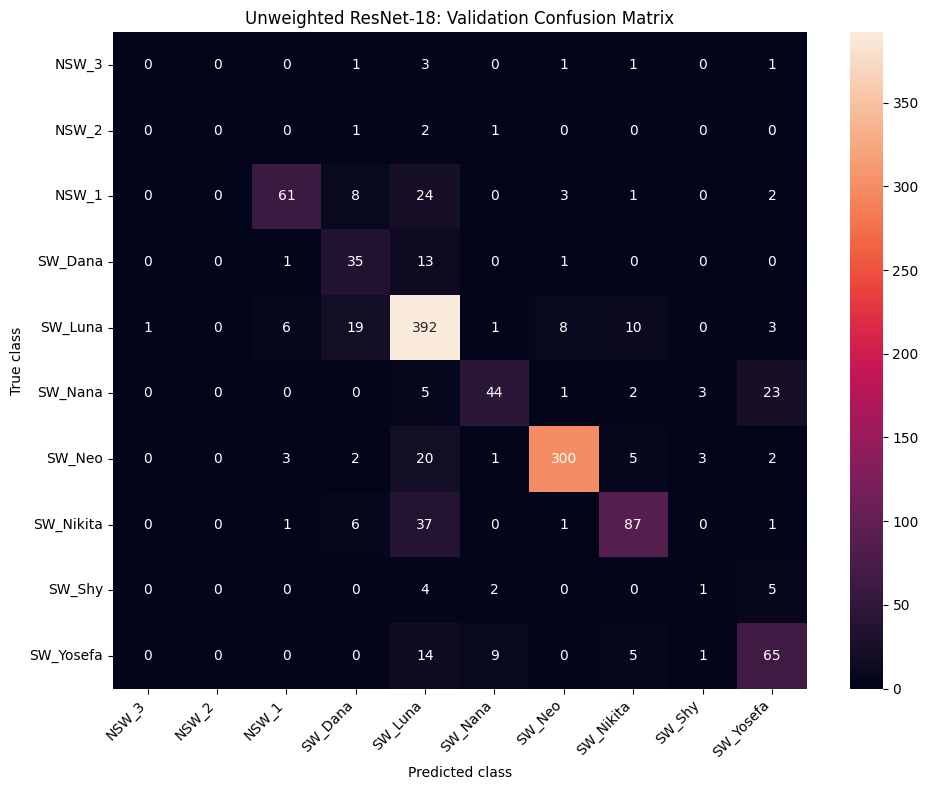

In [12]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import torch

model_unweighted.load_state_dict(
    torch.load(
        "openwhistle_resnet18_unweighted_best.pt",
        map_location=DEVICE
    )
)
model_unweighted.eval()

targets, predictions = [], []

with torch.no_grad():
    for x, y in val_loader:
        logits = model_unweighted(x.to(DEVICE))
        preds = logits.argmax(dim=1).cpu().numpy()

        targets.extend(y.numpy())
        predictions.extend(preds)

label_names = dataset["train"].features["label"].names
labels = list(range(10))

print(classification_report(
    targets,
    predictions,
    labels=labels,
    target_names=label_names,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(targets, predictions, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_names,
    yticklabels=label_names
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Unweighted ResNet-18: Validation Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


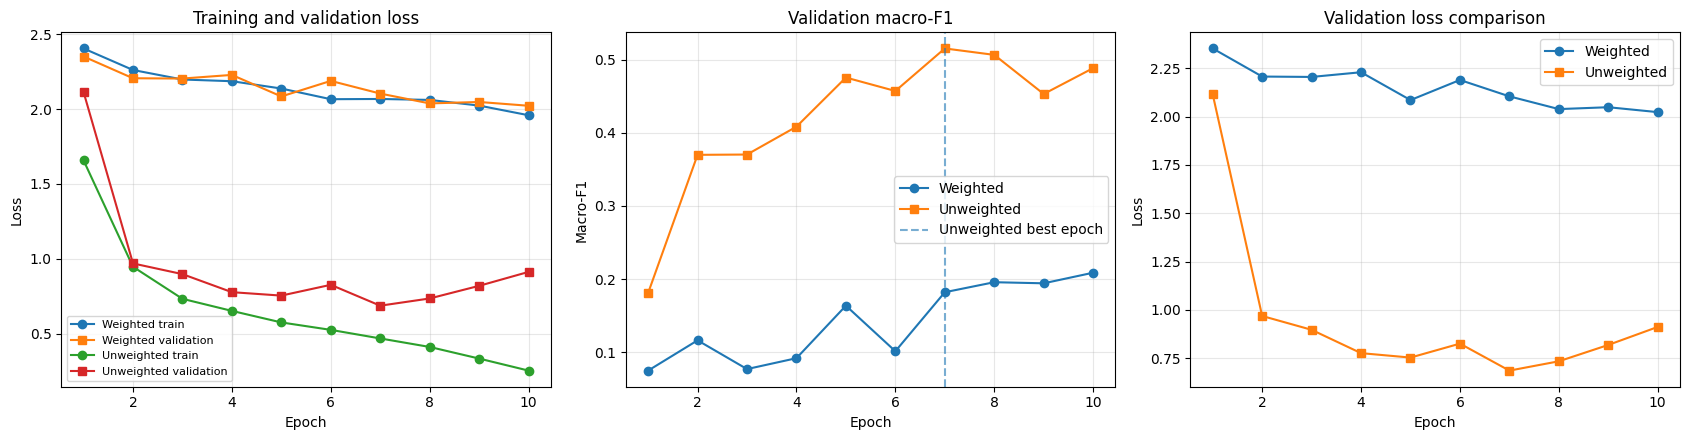

In [13]:

import matplotlib.pyplot as plt

epochs = range(1, 11)

# Experiment 1: Class-weighted cross-entropy
weighted_train_loss = [
    2.4057, 2.2617, 2.1981, 2.1867, 2.1378,
    2.0665, 2.0680, 2.0617, 2.0238, 1.9593
]
weighted_val_loss = [
    2.3518, 2.2065, 2.2045, 2.2288, 2.0849,
    2.1888, 2.1041, 2.0383, 2.0480, 2.0226
]
weighted_val_f1 = [
    0.0748, 0.1162, 0.0769, 0.0918, 0.1636,
    0.1013, 0.1820, 0.1957, 0.1942, 0.2087
]

# Experiment 2: Ordinary cross-entropy
unweighted_train_loss = [
    1.6581, 0.9467, 0.7325, 0.6518, 0.5747,
    0.5250, 0.4677, 0.4108, 0.3332, 0.2527
]
unweighted_val_loss = [
    2.1151, 0.9690, 0.8975, 0.7769, 0.7540,
    0.8261, 0.6866, 0.7348, 0.8193, 0.9124
]
unweighted_val_f1 = [
    0.1809, 0.3699, 0.3703, 0.4084, 0.4756,
    0.4572, 0.5154, 0.5066, 0.4531, 0.4885
]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Loss curves: weighted experiment
axes[0].plot(epochs, weighted_train_loss, marker="o",
             label="Weighted train")
axes[0].plot(epochs, weighted_val_loss, marker="s",
             label="Weighted validation")

# Loss curves: unweighted experiment
axes[0].plot(epochs, unweighted_train_loss, marker="o",
             label="Unweighted train")
axes[0].plot(epochs, unweighted_val_loss, marker="s",
             label="Unweighted validation")

axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Validation macro-F1
axes[1].plot(epochs, weighted_val_f1, marker="o",
             label="Weighted")
axes[1].plot(epochs, unweighted_val_f1, marker="s",
             label="Unweighted")
axes[1].axvline(7, linestyle="--", alpha=0.6,
                label="Unweighted best epoch")
axes[1].set_title("Validation macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Validation loss comparison
axes[2].plot(epochs, weighted_val_loss, marker="o",
             label="Weighted")
axes[2].plot(epochs, unweighted_val_loss, marker="s",
             label="Unweighted")
axes[2].set_title("Validation loss comparison")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()
